# Практическая работа № 6. Классификация текстов

**Автор:** Алмасов Арсен

**Цель:** сравнить CountVectorizer и TF-IDF с наивным байесовским классификатором для определения тональности отзывов.

## 1. Импорт библиотек и учебный корпус

In [1]:
import re
import string
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, classification_report

texts = [
    "Отличный фильм, мне очень понравилось",
    "Прекрасная история и хорошие актеры",
    "Очень интересный и качественный фильм",
    "Мне понравился сюжет и игра актеров",
    "Фильм просто замечательный",
    "Отличная работа, рекомендую посмотреть",
    "Очень хороший фильм и прекрасная музыка",
    "История захватывает с первых минут",
    "Актеры сыграли великолепно",
    "Фильм оставил приятные впечатления",
    "Мне было интересно смотреть до конца",
    "Качественная работа режиссера",
    "Прекрасный сюжет и отличная постановка",
    "Это один из лучших фильмов",
    "Фильм очень понравился всей семье",
    "Смотрел с удовольствием",
    "Очень сильная и интересная история",
    "Хорошие персонажи и отличный финал",
    "Мне понравилась каждая минута",
    "Фильм заслуживает высокой оценки",
    "Очень крутой фильм, советую всем",
    "Актерская игра на высоте",
    "Отличный сценарий и хорошая режиссура",
    "С удовольствием пересмотрю этот фильм",
    "Фильм получился ярким и увлекательным",
    "Прекрасные декорации и музыка",
    "История трогательная и красивая",
    "Все актеры отлично справились",
    "Очень достойное кино",
    "Мне понравилась атмосфера фильма",
    "Фильм оказался лучше ожиданий",
    "Отличное кино для выходного дня",
    "Сюжет интересный и хорошо продуман",
    "Фильм веселый и добрый",
    "Красивая история с хорошим концом",
    "Мне очень понравился этот фильм",
    "Сильная игра и отличный сюжет",
    "Фильм смотрится легко и интересно",
    "Рекомендую этот замечательный фильм",
    "Получил много положительных эмоций",
    "Ужасный фильм, зря потратил время",
    "Мне совсем не понравилось",
    "Скучный сюжет и плохая игра",
    "Фильм оказался очень слабым",
    "Плохой сценарий и ужасные диалоги",
    "Это худший фильм за последнее время",
    "Мне было скучно смотреть",
    "Актеры сыграли совершенно неубедительно",
    "Фильм разочаровал с первых минут",
    "История бессмысленная и затянутая",
    "Не рекомендую тратить на него время",
    "Ужасная постановка и плохой звук",
    "Фильм не оправдал ожиданий",
    "Сюжет запутанный и совершенно неинтересный",
    "Мне не понравились персонажи",
    "Очень слабый и скучный фильм",
    "Зря пошел в кино",
    "Фильм получился неудачным",
    "Ничего интересного в этом фильме нет",
    "Плохая актерская игра",
    "Фильм был слишком длинным и скучным",
    "Ужасная история и плохой финал",
    "Мне было жаль потраченного времени",
    "Фильм не стоит просмотра",
    "Слабый сценарий и скучные сцены",
    "Разочарован этим фильмом",
    "Фильм совершенно не зацепил",
    "Плохая режиссура и плохой монтаж",
    "Смотреть было неинтересно",
    "Этот фильм мне не понравился",
    "Сюжет плохой и предсказуемый",
    "Очень посредственное кино",
    "Не советую этот фильм",
    "Актеры не смогли спасти плохой сценарий",
    "Фильм скучный от начала до конца",
    "Потратил время зря",
    "Невнятная история и плохие диалоги",
    "Фильм оставил неприятное впечатление",
    "Мне не понравилась концовка",
    "Совершенно неинтересное кино",
    "Плохой фильм, не рекомендую"
]

labels = [1] * 40 + [0] * (len(texts) - 40)

df = pd.DataFrame({"text": texts, "label": labels})
print("Размер корпуса:", df.shape)
print("1 — положительный отзыв, 0 — отрицательный отзыв")
display(df.head())
print("\\nКоличество отзывов по классам:")
print(df["label"].value_counts())

Размер корпуса: (81, 2)
1 — положительный отзыв, 0 — отрицательный отзыв


,text,label
0,"Отличный фильм, мне очень понравилось",1
1,Прекрасная история и хорошие актеры,1
2,Очень интересный и качественный фильм,1
3,Мне понравился сюжет и игра актеров,1
4,Фильм просто замечательный,1


\nКоличество отзывов по классам:
label
0    41
1    40
Name: count, dtype: int64


## 2. Предобработка текста

In [2]:
# Приводим к нижнему регистру и удаляем пунктуацию и цифры.
# Слова отрицания не удаляем, так как они важны для тональности.
stop_words = {
    "и", "в", "во", "на", "это", "мне", "очень", "было",
    "для", "с", "со", "из", "за", "от", "до", "он", "она",
    "они", "его", "ее", "их", "но", "а", "как", "все"
}

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^а-яё\\s]", " ", text)
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return " ".join(words)

df["clean_text"] = df["text"].apply(clean_text)

display(df[["text", "clean_text", "label"]].head(10))
print("Пример очищенного текста:")
print(df["clean_text"].iloc[0])

,text,clean_text,label
0,"Отличный фильм, мне очень понравилось",отличный фильм понравилось,1
1,Прекрасная история и хорошие актеры,прекрасная история хорошие актеры,1
2,Очень интересный и качественный фильм,интересный качественный фильм,1
3,Мне понравился сюжет и игра актеров,понравился сюжет игра актеров,1
4,Фильм просто замечательный,фильм просто замечательный,1
5,"Отличная работа, рекомендую посмотреть",отличная работа рекомендую посмотреть,1
6,Очень хороший фильм и прекрасная музыка,хороший фильм прекрасная музыка,1
7,История захватывает с первых минут,история захватывает первых минут,1
8,Актеры сыграли великолепно,актеры сыграли великолепно,1
9,Фильм оставил приятные впечатления,фильм оставил приятные впечатления,1


Пример очищенного текста:
отличный фильм понравилось


## 3. Разделение на train и test

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"],
    df["label"],
    test_size=0.25,
    random_state=42,
    stratify=df["label"]
)

print("Обучающая выборка:", len(X_train))
print("Тестовая выборка:", len(X_test))
print("Разделение выполнено до обучения векторизаторов.")

Обучающая выборка: 60
Тестовая выборка: 21
Разделение выполнено до обучения векторизаторов.


## 4. Вариант 1 — CountVectorizer

In [4]:
count_vectorizer = CountVectorizer()
X_train_count = count_vectorizer.fit_transform(X_train)
X_test_count = count_vectorizer.transform(X_test)

count_model = MultinomialNB()
count_model.fit(X_train_count, y_train)
count_pred = count_model.predict(X_test_count)

count_accuracy = accuracy_score(y_test, count_pred)
count_f1 = f1_score(y_test, count_pred, zero_division=0)

print("Размерность матрицы признаков CountVectorizer:", X_train_count.shape)
print(f"Accuracy: {count_accuracy:.3f}")
print(f"F1: {count_f1:.3f}")

Размерность матрицы признаков CountVectorizer: (60, 116)
Accuracy: 0.762
F1: 0.706


## 5. Вариант 2 — TF-IDF

In [5]:
tfidf_vectorizer = TfidfVectorizer()
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

tfidf_model = MultinomialNB()
tfidf_model.fit(X_train_tfidf, y_train)
tfidf_pred = tfidf_model.predict(X_test_tfidf)

tfidf_accuracy = accuracy_score(y_test, tfidf_pred)
tfidf_f1 = f1_score(y_test, tfidf_pred, zero_division=0)

print("Размерность матрицы признаков TF-IDF:", X_train_tfidf.shape)
print(f"Accuracy: {tfidf_accuracy:.3f}")
print(f"F1: {tfidf_f1:.3f}")

Размерность матрицы признаков TF-IDF: (60, 116)
Accuracy: 0.810
F1: 0.750


## 6. Сравнение результатов

,Метод,Accuracy,F1
0,CountVectorizer,0.762,0.706
1,TfidfVectorizer,0.810,0.750


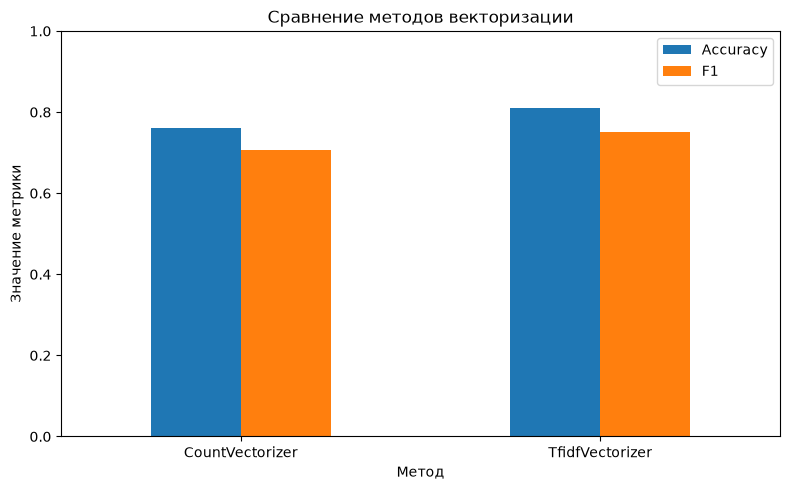

По F1 на этом тестовом наборе лучше сработал TF-IDF.


In [6]:
results = pd.DataFrame({
    "Метод": ["CountVectorizer", "TfidfVectorizer"],
    "Accuracy": [count_accuracy, tfidf_accuracy],
    "F1": [count_f1, tfidf_f1]
})

display(results.round(3))

results.set_index("Метод")[["Accuracy", "F1"]].plot(
    kind="bar", ylim=(0, 1), figsize=(8, 5)
)
plt.title("Сравнение методов векторизации")
plt.ylabel("Значение метрики")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

if tfidf_f1 > count_f1:
    print("По F1 на этом тестовом наборе лучше сработал TF-IDF.")
elif count_f1 > tfidf_f1:
    print("По F1 на этом тестовом наборе лучше сработал CountVectorizer.")
else:
    print("По F1 оба метода показали одинаковый результат.")

## 7. Примеры ошибок модели

In [7]:
# Для анализа используем предсказания TF-IDF модели.
error_df = pd.DataFrame({
    "Текст": X_test.to_numpy(),
    "Истинная метка": y_test.to_numpy(),
    "Предсказание": tfidf_pred
})

errors = error_df[error_df["Истинная метка"] != error_df["Предсказание"]]

print("Количество ошибок TF-IDF модели:", len(errors))
if len(errors) == 0:
    print("На этой тестовой выборке ошибок нет. Это не гарантирует идеальную работу на новых текстах.")
else:
    display(errors.head(5))
    print("Возможные причины: маленький корпус, мало контекста, неоднозначные слова или отрицание.")

Количество ошибок TF-IDF модели: 4


,Текст,Истинная метка,Предсказание
1,получил много положительных эмоций,1,0
3,один лучших фильмов,1,0
4,крутой фильм советую всем,1,0
9,фильм получился ярким увлекательным,1,0


Возможные причины: маленький корпус, мало контекста, неоднозначные слова или отрицание.


## 8. Выводы

- Тексты приведены к нижнему регистру, из них удалены пунктуация, цифры и часть стоп-слов.
- Корпус разделён на обучающую и тестовую выборки до обучения векторизаторов.
- CountVectorizer представляет текст через частоты слов.
- TF-IDF учитывает, насколько важны слова для отдельных документов.
- Оба метода использованы с MultinomialNB.
- Accuracy показывает долю правильных предсказаний, а F1 учитывает Precision и Recall.
- Лучший метод определяется по фактически полученным метрикам, а не заранее.
- Корпус небольшой и учебный, поэтому результаты не следует считать доказательством качества на реальных отзывах.